# Lesson 19 - Why fishing boats are hard, and two fixes that don't work

In lesson 16 (five classes, engineered features, gradient boosting), fishing boats were the weakest class: right
for 43 % of their clips, often called tug or pleasure craft. This lesson looks at why, and tries two fixes, both
decided on the validation folds only:

1. **Tree size.** Gradient boosting has used the same setting since lesson 13 (15 leaves per tree, at least 50
   clips per leaf). Six settings are compared.
2. **Class offsets.** One number per class is added to the model's log-probabilities before choosing the class,
   chosen to give the best balanced accuracy on the validation clips. This moves the borderline towards classes
   the model calls too rarely.

```
python src/fishing_boost.py      # -> runs/fishing_boost/ (CPU, about 15 minutes)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import fishing_boost as FB
import five_classes as F5
from paths import DATA_DIR

p16 = pd.read_parquet(F5.OUT_DIR / "predictions.parquet")
p16 = p16[(p16.features == "engineered") & (p16.model == "gradient boosting")].copy()
table = pd.read_parquet(DATA_DIR / "clips.parquet")
p16["dist"] = table.mean_distance.to_numpy()[p16.row]
P5 = [f"p_{c}" for c in F5.CLASSES5]
p16["called"] = np.array(F5.CLASSES5)[p16[P5].to_numpy().argmax(1)]
pd.set_option("display.width", 160)

## 1. Why fishing boats are hard

What fishing clips are called, by distance (lesson 16's predictions, all test folds):

called       background  cargo + tanker  fishing  pleasurecraft  tug  clips
distance                                                                   
0-500 m               0               8       44              4   44    208
500-1000 m            1               2       51             14   32    697
1000-1500 m           8               2       44             21   26    936
1500-2000 m          15               4       39             20   21   1752


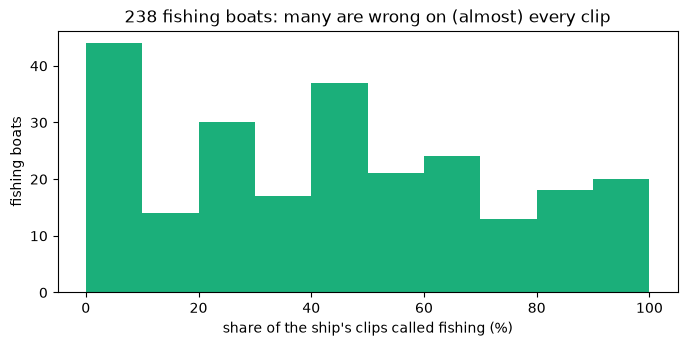

ships right on under 20 % of their clips: 58, on over 80 %: 27
when a fishing clip is called something else, fishing is the second choice 64% of the time


In [2]:
fish = p16[p16.y == F5.CLASSES5.index("fishing")].copy()
fish["distance"] = pd.cut(fish.dist, [0, 500, 1000, 1500, 2000], labels=["0-500 m", "500-1000 m", "1000-1500 m",
                                                                         "1500-2000 m"])
print((100 * pd.crosstab(fish.distance, fish.called, normalize="index")).round(0).astype(int)
      .assign(clips=fish.groupby("distance", observed=True).size()))

per_ship = fish.groupby("ship").called.apply(lambda c: (c == "fishing").mean())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(100 * per_ship, bins=np.arange(0, 101, 10), color="#1baf7a")
ax.set_xlabel("share of the ship's clips called fishing (%)"); ax.set_ylabel("fishing boats")
ax.set_title(f"{len(per_ship)} fishing boats: many are wrong on (almost) every clip"); plt.show()

wrong = fish[fish.called != "fishing"]
second = (wrong[P5].to_numpy().argsort(1)[:, -2] == F5.CLASSES5.index("fishing")).mean()
print(f"ships right on under 20 % of their clips: {(per_ship < 0.2).sum()}, on over 80 %: {(per_ship > 0.8).sum()}")
print(f"when a fishing clip is called something else, fishing is the second choice {second:.0%} of the time")

- **It is not distance:** even closer than 500 m, 44 % of the fishing clips are called tug. Far away, more are
  called background or pleasure craft, as the boat fades into the noise.
- **It is the boats:** the errors stick to ships. 58 of 238 fishing boats are right on fewer than 20 % of their
  clips, and only 27 on more than 80 %. Many fishing boats simply sound like tugs: both are working boats with
  diesel engines of similar size, and "fishing" in the AIS data covers boats from small trollers to trawlers.
- **But fishing is often the second choice** (64 % of the wrong clips), which is why moving the borderline seemed
  worth a try.

## 2. The two fixes

In [3]:
s = json.loads((FB.OUT_DIR / "results.json").read_text())
search = pd.read_csv(FB.OUT_DIR / "tree_search.csv")
print("validation balanced accuracy by tree size (mean of 5 folds, %):")
print((100 * search.groupby(["leaves", "min_leaf"]).val_balanced_accuracy.mean()).round(1).unstack())
print(f"\nchosen: {s['chosen_trees']}")
print("\nclass offsets chosen on validation (per fold; 0 = no change, negative = called less often):")
print(pd.DataFrame(s["offsets"]).T.round(1))

validation balanced accuracy by tree size (mean of 5 folds, %):
min_leaf    20    50
leaves              
15        69.4  69.5
31        69.5  69.7
63        69.2  69.2

chosen: {'leaves': 31, 'min_leaf': 50}

class offsets chosen on validation (per fold; 0 = no change, negative = called less often):
   background  cargo + tanker  fishing  pleasurecraft  tug
1         0.0            -0.5      0.0            0.0  0.0
2         0.0            -0.4      0.1            0.4  0.1
3         0.0            -0.6      0.0            0.1  0.0
4         0.0            -0.7      0.0           -0.5  0.0
5         0.0            -0.3     -0.1            0.0  0.0


                             per clip (%)  per ship (%)  recall background  recall cargo + tanker  recall fishing  recall pleasurecraft  recall tug
version                                                                                                                                            
lesson 16 setting                    69.9          78.9               85.3                   96.3            43.0                  63.1        61.6
tuned trees                          70.0          79.1               85.6                   96.3            42.6                  64.0        61.6
tuned trees + class offsets          69.9          78.6               85.9                   95.5            42.1                  63.0        62.7


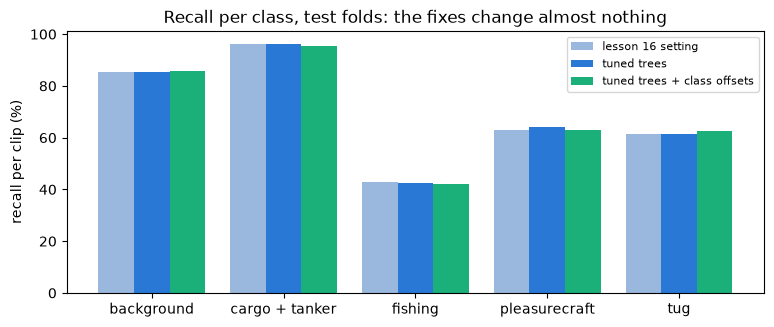

In [4]:
res = pd.DataFrame(s["results"])
order = ["lesson 16 setting", "tuned trees", "tuned trees + class offsets"]
g = res.groupby("version")[["balanced_accuracy", "per_ship_balanced_accuracy"]].agg(["mean", "std"]).loc[order]
rec = pd.DataFrame(list(res.per_class_recall)).assign(version=res.version).groupby("version").mean().loc[order]
show = pd.DataFrame({"per clip (%)": (100 * g[("balanced_accuracy", "mean")]).round(1),
                     "per ship (%)": (100 * g[("per_ship_balanced_accuracy", "mean")]).round(1)})
print(pd.concat([show, (100 * rec).round(1).add_prefix("recall ")], axis=1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(F5.CLASSES5))
for i, (v, color) in enumerate(zip(order, ["#9ab8de", "#2a78d6", "#1baf7a"])):
    ax.bar(x + (i - 1) * 0.27, 100 * rec.loc[v], 0.27, color=color, label=v)
ax.set_xticks(x, F5.CLASSES5); ax.set_ylabel("recall per clip (%)"); ax.legend(fontsize=8)
ax.set_title("Recall per class, test folds: the fixes change almost nothing"); plt.show()

## 3. What it means

- **Neither fix helps fishing boats** (recall 43.0 % → 42.6 % → 42.1 %) or the overall score (69.9-70.0 % per
  clip, 78.6-79.1 % per ship: all within the fold-to-fold spread).
- **Tree size doesn't matter:** all six settings are within half a point on validation; lesson 13's setting was
  already fine.
- **The offsets learnt something else:** on validation, the best move was to call cargo + tanker a little less
  often, not to call fishing more often. Pushing towards fishing would turn as many tugs and pleasure craft into
  "fishing" as it would win back.
- **The limit is in the sound, not the model:** many fishing boats sound like tugs. Better fishing results would
  need information these features don't have: for example the boat's size, or its behaviour over a longer time
  (trawling at a steady low speed), or a merged "small working boat" class (fishing + tug) if the professor agrees.
- **Lesson 16's model stays as it is.**